# Tarea 01 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

1. Aplica análisis y exploración de datos al dataset WineDataset.csv, realiza 8 gráficas con seaborn y añade una explicación de lo que representa Más información del dataset en: https://archive.ics.uci.edu/dataset/109/wine
2. Aplica KNN a este dataset. Usa cv de 5 folds y GridSearchCV. ¿De cuánto es el accuracy? Aunque los datos tengan variabilidad, todavía no escales.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

attributes = [
    "Class",
    "Alcohol",
    "Malic acid",
    "Ash",
    "Alkalinity of ash",
    "Magnesium",
    "Total phenols",
    "Flavonoids",
    "Nonflavonoid phenols",
    "Proanthocyanins",
    "Color intensity",
    "Hue",
    "OD280/OD315", # of diluted wines
    "Proline"
]

df = pd.read_csv("./WineDataset.csv", sep=",", names=attributes)

df.head()

,Class,Alcohol,Malic acid,Ash,Alkalinity of ash,Magnesium,Total phenols,Flavonoids,Nonflavonoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## Observación del dataset

Entre las variables la que nos podría interesar como variable objetivo es la clase, es decir, poder identificar un tipo de vino a partir de sus demás atributos

## Gráficas

### 1. Distribución de las clases de vino

En la primera gráfica se puede observar que hay más registros del vino de **Clase 2**

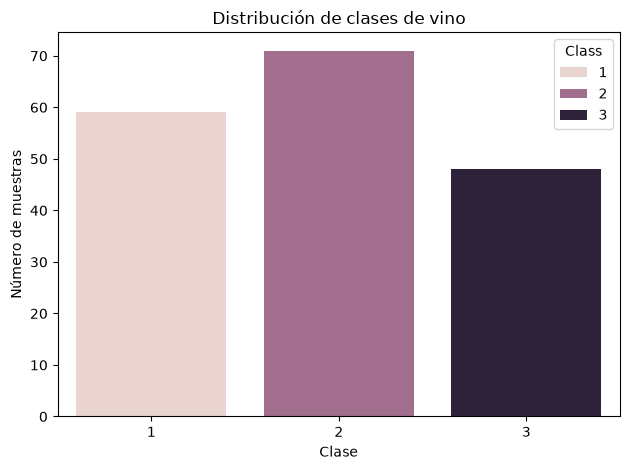

In [2]:
sns.countplot(data=df, x="Class", hue="Class")
plt.title('Distribución de clases de vino')
plt.xlabel('Clase')
plt.ylabel('Número de muestras')
plt.tight_layout()
plt.show()

### 2. Correlación de variables

Los atributos con mayor correlación:
- Fenoles totales y Flavonoides
- Alcohol e intensidad de color
- Flavonoides y OD280/OD315
- Fenoles totales y OD280/OD315

Atributos con menor correlación:
- Ácido málico y tonalidad
- Alcalinidad y prolina
- Flavonoides y fenoles no flavonoides
- Intensidad de color y tonalidad

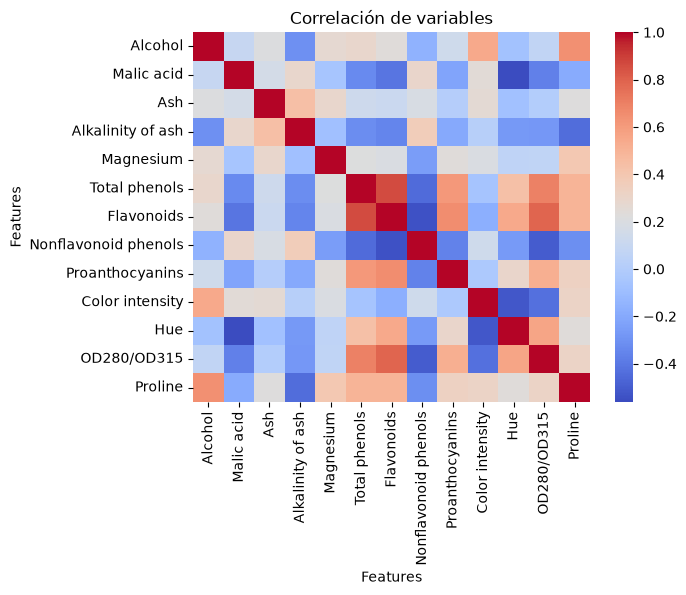

In [3]:
sns.heatmap(data=df.iloc[:, 1:].corr(), annot=False, cmap="coolwarm")
plt.title('Correlación de variables')
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

### 3. Tonalidad del vino y flavonoides

En la gráfica se puede observar que la clase de vino 1 tiene más flavonoides, lo que causa que la tonalidad (hue) sea mayor.

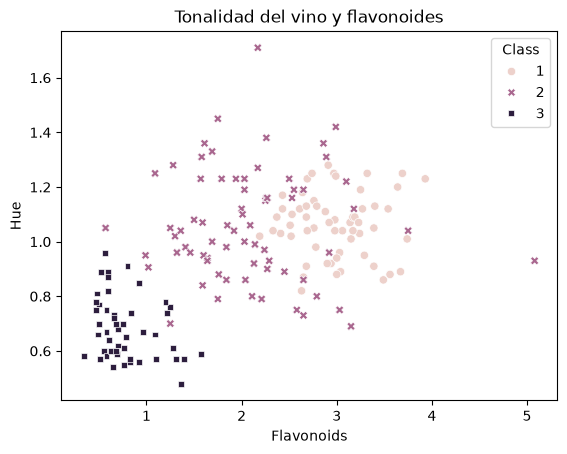

In [4]:
sns.scatterplot(data=df, x="Flavonoids", y="Hue", hue="Class", style='Class')
plt.title("Tonalidad del vino y flavonoides")
plt.xlabel("Flavonoids")
plt.ylabel("Hue")
plt.show()

### 4. Variabilidad de alcohol por clase

La clase 1 tiene más valores atípicos, la media y el tamaño de la caja se concentran en un valor muy específico, la mayoría de los datos no se alejan de la media.
La clase 2 mayor variabilidad.

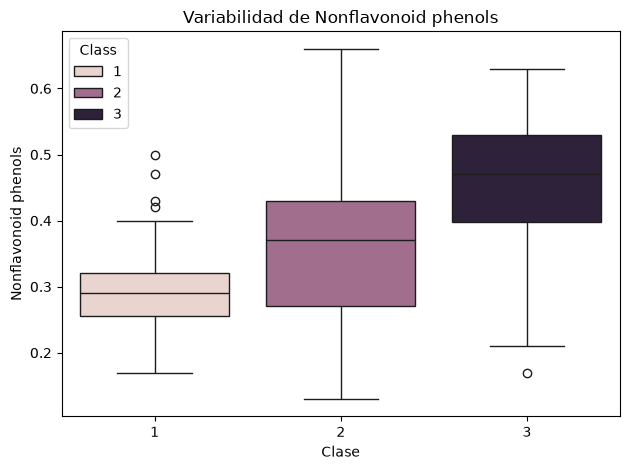

In [5]:
sns.boxplot(data=df, x="Class", y="Nonflavonoid phenols", hue="Class")
plt.title("Variabilidad de Nonflavonoid phenols")
plt.xlabel("Clase")
plt.ylabel("Nonflavonoid phenols")
plt.tight_layout()
plt.show()

### 5. Flavonoides y la relación de absorbancia óptica

La relación de la absorbancia óptica a 280 nm y 315 nm que evalúa el contenido de proteínas/flavonoides en el análisis químico del vino.

<!-- Fuente: Mi hermana estudia QFB -->

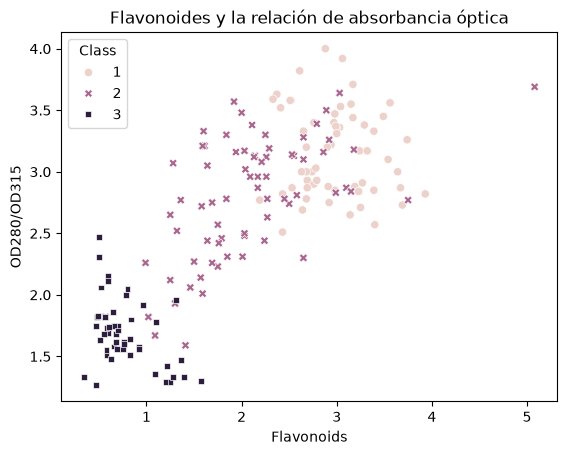

In [6]:
sns.scatterplot(data=df, x="Flavonoids", y="OD280/OD315", hue="Class", style='Class')
plt.title("Flavonoides y la relación de absorbancia óptica")
plt.xlabel("Flavonoids")
plt.ylabel("OD280/OD315")
plt.show()

### 6. Distribución de Prolina por Clase

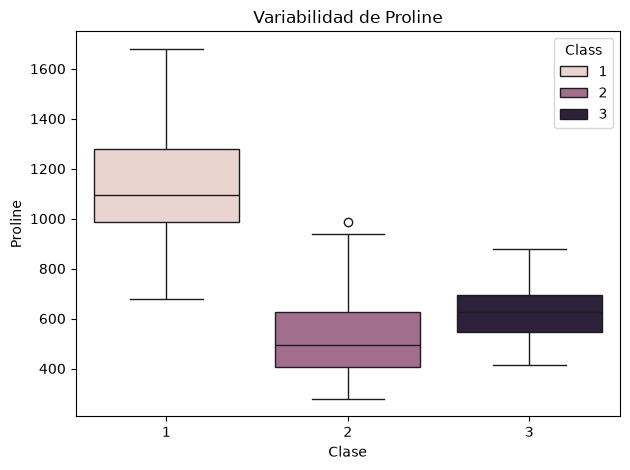

In [7]:
sns.boxplot(data=df, x="Class", y="Proline", hue="Class")
plt.title("Variabilidad de Proline")
plt.xlabel("Clase")
plt.ylabel("Proline")
plt.tight_layout()
plt.show()

### 7. Ácido málico y tonalidad

En el heatmap se observó que estos dos atributos no tenían mucha correlación, y se confirma haciendo un scatterplot de ambos atributos, ya que los puntos se distribuyen más extensamente.

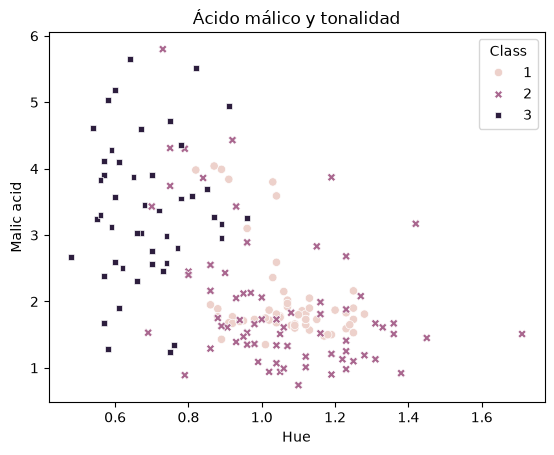

In [8]:
sns.scatterplot(data=df, x="Hue", y="Malic acid", hue="Class", style='Class')
plt.title("Ácido málico y tonalidad")
plt.xlabel("Hue")
plt.ylabel("Malic acid")
plt.show()

### 8. Histograma de la clase 2 con los fenoles no flavonoides

Se puede observar que la clase 3 tiene mayor sesgo por la izquierda, y la clase 1 por la derecha;
la clase 2 tiene un comportamiento más simétrico, es decir, un comportamiento más normal, pero distribuido a lo largo de todo el rango.

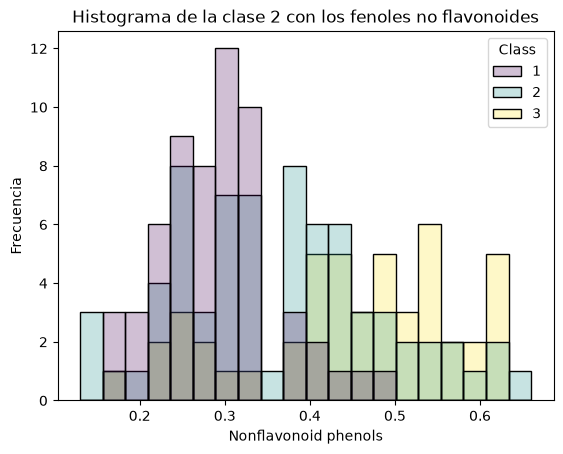

In [9]:
sns.histplot(data=df, x="Nonflavonoid phenols", bins=20, hue="Class", alpha=0.25, palette="viridis")
plt.title("Histograma de la clase 2 con los fenoles no flavonoides")
plt.xlabel("Nonflavonoid phenols")
plt.ylabel("Frecuencia")
plt.show()

## Aplicación de KNN en el dataset

In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

x = df.iloc[:, 1:]
y = df.iloc[:, 0]

knn = KNeighborsClassifier()

parameters = {
    "n_neighbors": [5, 7, 10, 15, 20],
    "weights": ["uniform", "distance"],
    "metric": ["minkowski", "manhattan"]
}

grid = GridSearchCV(estimator=knn,
                    param_grid=parameters,
                    cv=5,
                    scoring='accuracy')

grid.fit(x, y)

print(f"Best hyperparameters: {grid.best_params_}")
print(f"Best Accuracy: {grid.best_score_ * 100:.2f}%")
print(f"Best score: {grid.best_score_ * 100:.2f}")


Best hyperparameters: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best Accuracy: 78.71%
Best score: 78.71
